# Deepfake Detection Project

## Custom Convolutional Neural Network

This notebook develops a baseline Convolutional Neural Network (CNN) for classifying facial images as real or deepfake using the leakage-safe train, validation, and test partitions created during the dataset audit.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.22.0-rc1


In [3]:
print(tf.config.list_physical_devices("GPU"))


[]


In [4]:
manifest = pd.read_csv(
    "../data/celeb_df_clean_manifest.csv"
)

print("Total images:", len(manifest))

print(pd.crosstab(
    manifest["clean_split"],
    manifest["label"]
))

Total images: 101031
label         fake   real
clean_split              
test          5179   5020
train        40619  40375
val           4873   4965


In [5]:
label_map = {
    "real": 0,
    "fake": 1
}

manifest["target"] = manifest["label"].map(label_map)

print(manifest[["label", "target"]].drop_duplicates())

      label  target
0      real       0
50360  fake       1


In [6]:
train_df = manifest[
    manifest["clean_split"] == "train"
].copy()

val_df = manifest[
    manifest["clean_split"] == "val"
].copy()

test_df = manifest[
    manifest["clean_split"] == "test"
].copy()

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

Training images: 80994
Validation images: 9838
Testing images: 10199


In [7]:
from pathlib import Path

for name, data in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    missing = (~data["path"].apply(lambda x: Path(x).exists())).sum()
    print(name, "missing paths:", missing)

Train missing paths: 0
Validation missing paths: 0
Test missing paths: 0


In [8]:
IMG_SIZE = (256, 256)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

In [9]:
def load_image(path, label):
    image = tf.io.read_file(path)

    image = tf.image.decode_jpeg(
        image,
        channels=3
    )

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = tf.cast(
        image,
        tf.float32
    )

    return image, label

In [10]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (
        train_df["path"].values,
        train_df["target"].values
    )
)

train_ds = train_ds.map(
    load_image,
    num_parallel_calls=AUTOTUNE
)

In [11]:
val_ds = tf.data.Dataset.from_tensor_slices(
    (
        val_df["path"].values,
        val_df["target"].values
    )
)

val_ds = val_ds.map(
    load_image,
    num_parallel_calls=AUTOTUNE
)

In [12]:
test_ds = tf.data.Dataset.from_tensor_slices(
    (
        test_df["path"].values,
        test_df["target"].values
    )
)

test_ds = test_ds.map(
    load_image,
    num_parallel_calls=AUTOTUNE
)

In [13]:
train_ds = (
    train_ds
    .shuffle(
        buffer_size=5000,
        seed=42
    )
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    val_ds
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    test_ds
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

In [14]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (32, 256, 256, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 255.0


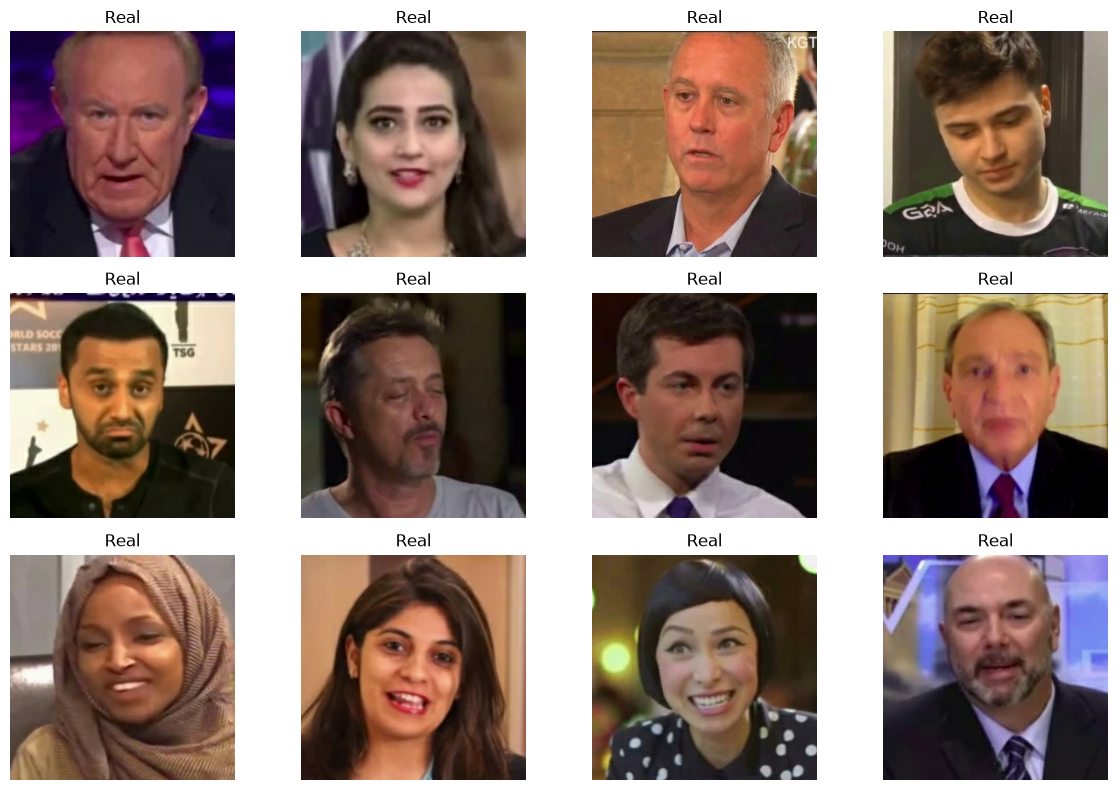

In [15]:
for images, labels in train_ds.take(1):

    plt.figure(figsize=(12, 8))

    for i in range(12):
        ax = plt.subplot(3, 4, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        label = "Fake" if labels[i].numpy() == 1 else "Real"

        plt.title(label)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [16]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.10),
        layers.RandomTranslation(
            height_factor=0.05,
            width_factor=0.05
        )
    ],
    name="data_augmentation"
)

In [17]:
model = keras.Sequential([
    
    layers.Input(shape=(256, 256, 3)),

    data_augmentation,

    layers.Rescaling(1.0 / 255),

    layers.Conv2D(
        32,
        kernel_size=3,
        padding="same",
        activation="relu"
    ),
    layers.MaxPooling2D(),

    layers.Conv2D(
        64,
        kernel_size=3,
        padding="same",
        activation="relu"
    ),
    layers.MaxPooling2D(),

    layers.Conv2D(
        128,
        kernel_size=3,
        padding="same",
        activation="relu"
    ),
    layers.MaxPooling2D(),

    layers.Conv2D(
        256,
        kernel_size=3,
        padding="same",
        activation="relu"
    ),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.5),

    layers.Dense(
        1,
        activation="sigmoid"
    )
])

In [18]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 256, 256, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,441 (1.61 MB)

 Trainable params: 421,441 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc")
    ]
)

In [20]:
callbacks = [

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    ),

    keras.callbacks.ModelCheckpoint(
        "../models/custom_cnn_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

In [21]:
from pathlib import Path

Path("../models").mkdir(
    exist_ok=True
)

In [22]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3,
    callbacks=callbacks
)

Epoch 1/3


C:\Users\urshi\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


 352/2532 ━━━━━━━━━━━━━━━━━━━━ 1:49:02 3s/step - accuracy: 0.9990 - auc: 0.0000e+00 - loss: 0.0053 - precision: 0.0000e+00 - recall: 0.0000e+00


KeyboardInterrupt

